# Activity 1: Multiple Linear Regression

## 1. Dataset Selection and Description

**Dataset Name:** California Housing Dataset

**Dataset Source:** https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

**Dataset Documentation:** https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_california_housing.html

**File Type:** CSV-style tabular dataset, loaded through the Scikit-learn library.

**Number of Observations:** 20,640

**Number of Input Features:** 8

**Number of Columns:** 9, including the target variable.

### Dataset Description

The California Housing dataset contains information about housing districts in California. It includes household income, average rooms, house age, population, and geographical information. The dataset is used to predict the median house value of a district.

### Input Features

| Feature | Description | Unit |
|---|---|---|
| MedInc | Median household income | $10,000 |
| HouseAge | Median house age | Years |
| AveRooms | Average rooms per household | Rooms |
| AveBedrms | Average bedrooms per household | Bedrooms |
| Population | District population | Persons |
| AveOccup | Average household occupancy | Persons |
| Latitude | Geographical latitude | Degrees |
| Longitude | Geographical longitude | Degrees |

### Target Variable

**MedHouseVal:** Median house value in units of $100,000.

### Problem Statement

To predict the median house value using multiple numerical input features. The performance of a multiple linear regression model will be compared with a single-feature regression model to determine whether the additional features improve prediction accuracy.

In [1]:
# Step 1: Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_style("whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Dataset Loading, Inspection and Cleaning

The California Housing dataset is loaded using Scikit-learn. The first five records, data types, summary statistics, missing values, and duplicate records are examined.

The dataset is checked for missing and duplicate records before model development. Invalid or missing records are handled to ensure that the model is trained on clean data.

The target variable is MedHouseVal, while the remaining eight numerical columns are selected as input features.

In [2]:
# Step 2: Load the dataset

housing = fetch_california_housing(as_frame=True)

df = housing.frame.copy()

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

print("\nFirst five records:")
display(df.head())

Dataset loaded successfully.
Dataset shape: (20640, 9)

First five records:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
# Display dataset information

print("Dataset Information:")
df.info()

print("\nSummary Statistics:")
display(df.describe().T)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Summary Statistics:


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010



Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate Records:
0


In [4]:
# Remove duplicate and missing records

df = df.drop_duplicates().dropna().copy()

# Separate input features and target

X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

print("Dataset after cleaning:", df.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Variable:", y.name)

print("\nFeature Ranges:")
for column in X.columns:
    print(
        column,
        "Minimum:", X[column].min(),
        "Maximum:", X[column].max()
    )

Dataset after cleaning: (20640, 9)

Input Features:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Target Variable: MedHouseVal

Feature Ranges:
MedInc Minimum: 0.4999 Maximum: 15.0001
HouseAge Minimum: 1.0 Maximum: 52.0
AveRooms Minimum: 0.8461538461538461 Maximum: 141.9090909090909
AveBedrms Minimum: 0.3333333333333333 Maximum: 34.06666666666667
Population Minimum: 3.0 Maximum: 35682.0
AveOccup Minimum: 0.6923076923076923 Maximum: 1243.3333333333333
Latitude Minimum: 32.54 Maximum: 41.95
Longitude Minimum: -124.35 Maximum: -114.31


## 3. Visualisation and Correlation Analysis

Scatter plots are created to study the relationship between each input feature and the target variable. A correlation matrix and heatmap are used to understand the direction and strength of the relationships.

Positive correlation means that two variables tend to increase together, while negative correlation means that they tend to move in opposite directions.

Correlation between input features is also examined to identify possible multicollinearity.

A strong correlation does not necessarily prove that one variable causes another.

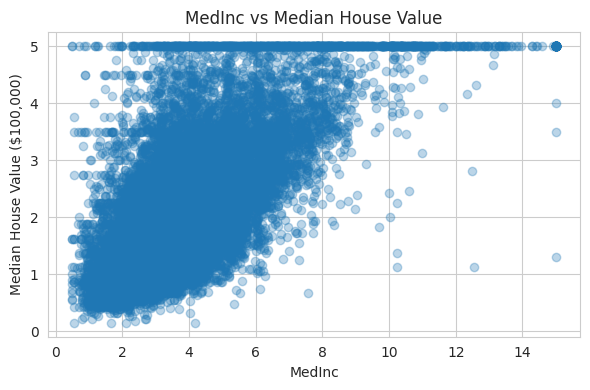

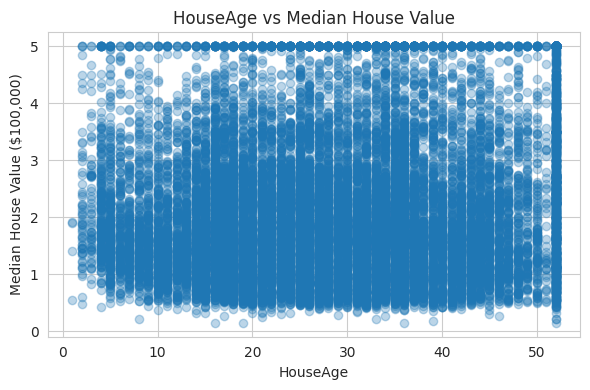

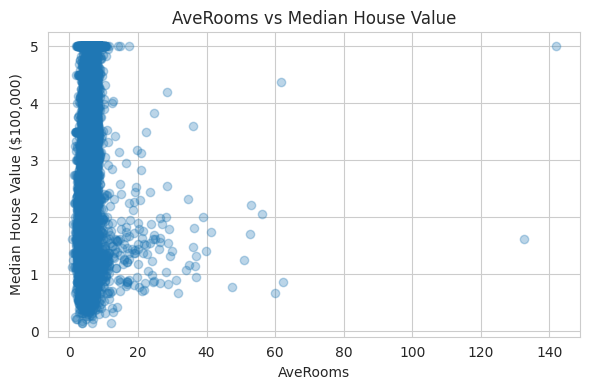

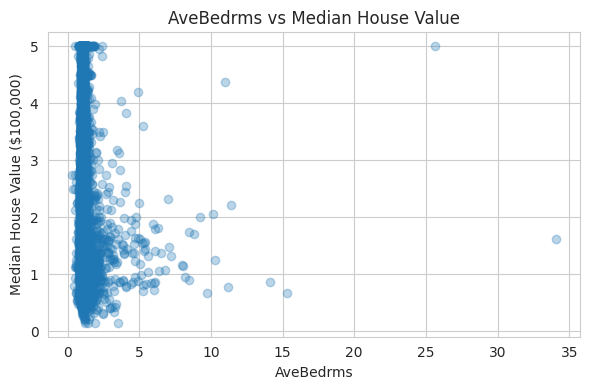

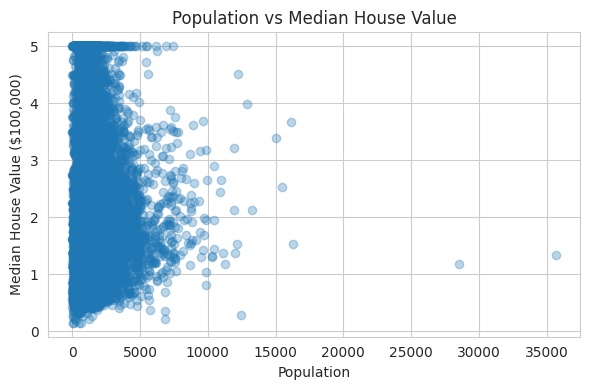

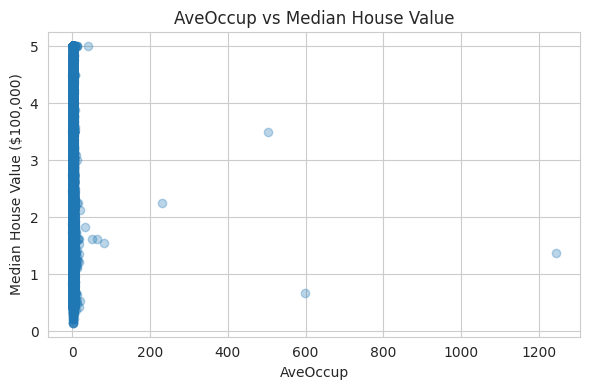

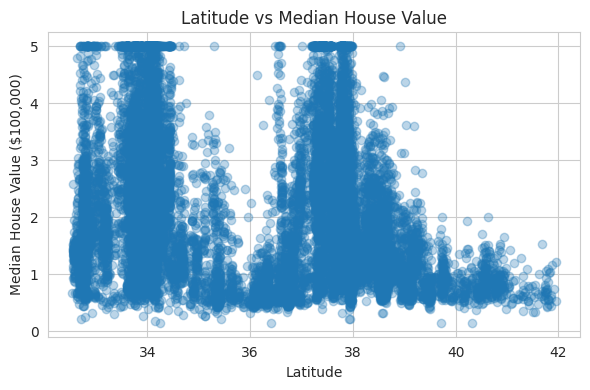

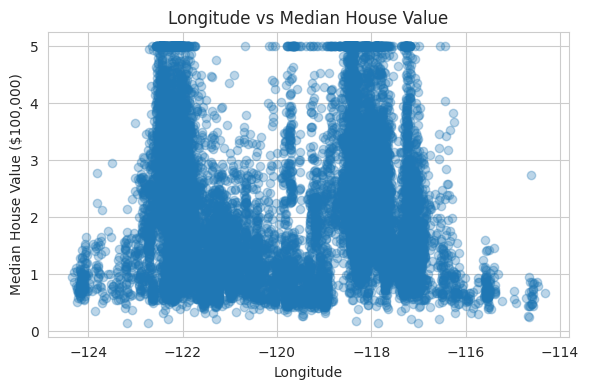

In [5]:
# Plot each input feature against the target

for column in X.columns:

    plt.figure(figsize=(6, 4))

    plt.scatter(X[column], y, alpha=0.3)

    plt.title(f"{column} vs Median House Value")
    plt.xlabel(column)
    plt.ylabel("Median House Value ($100,000)")

    plt.tight_layout()
    plt.show()

Correlation Matrix:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
MedInc,1.000,-0.119,0.327,-0.062,0.005,0.019,-0.080,-0.015,0.688
HouseAge,-0.119,1.000,-0.153,-0.078,-0.296,0.013,0.011,-0.108,0.106
AveRooms,0.327,-0.153,1.000,0.848,-0.072,-0.005,0.106,-0.028,0.152
AveBedrms,-0.062,-0.078,0.848,1.000,-0.066,-0.006,0.070,0.013,-0.047
Population,0.005,-0.296,-0.072,-0.066,1.000,0.070,-0.109,0.100,-0.025
AveOccup,0.019,0.013,-0.005,-0.006,0.070,1.000,0.002,0.002,-0.024
Latitude,-0.080,0.011,0.106,0.070,-0.109,0.002,1.000,-0.925,-0.144
Longitude,-0.015,-0.108,-0.028,0.013,0.100,0.002,-0.925,1.000,-0.046
MedHouseVal,0.688,0.106,0.152,-0.047,-0.025,-0.024,-0.144,-0.046,1.000


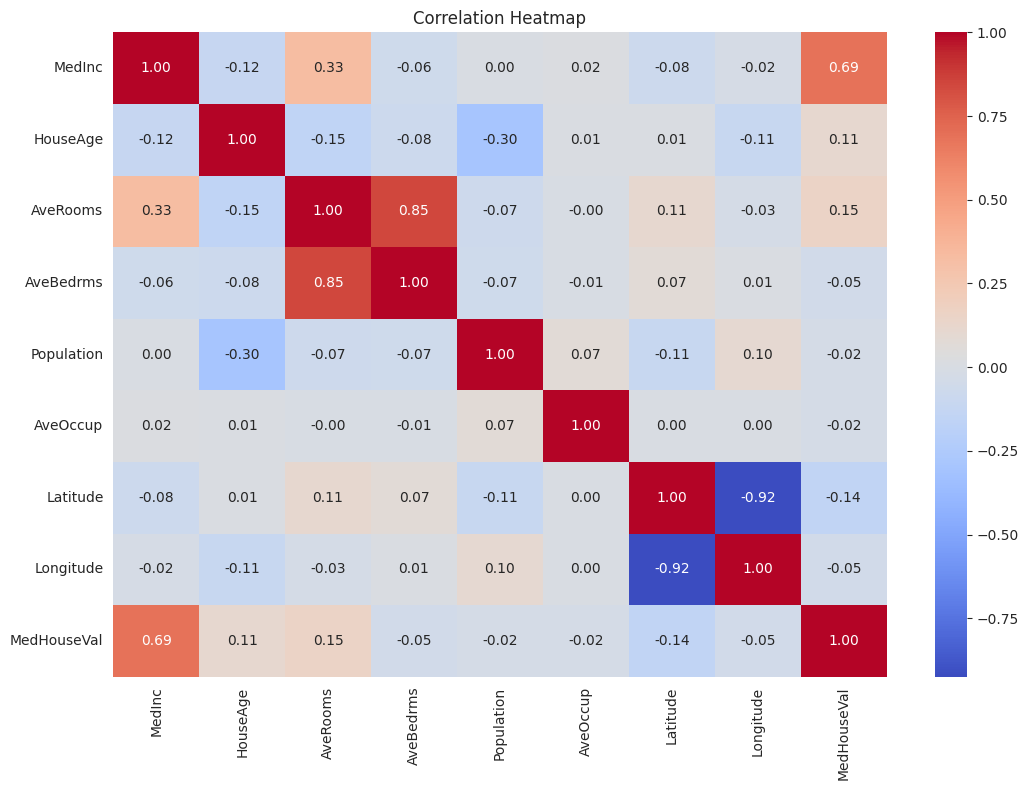


Correlation with Target:


,MedHouseVal
MedInc,0.688075
AveRooms,0.151948
Latitude,-0.144160
HouseAge,0.105623
AveBedrms,-0.046701
Longitude,-0.045967
Population,-0.024650
AveOccup,-0.023737


In [6]:
# Calculate correlation matrix

correlation_matrix = df.corr()

print("Correlation Matrix:")
display(correlation_matrix.round(3))

# Plot heatmap

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# Display feature-target correlations

print("\nCorrelation with Target:")

display(
    correlation_matrix["MedHouseVal"]
    .drop("MedHouseVal")
    .sort_values(key=abs, ascending=False)
)

## 4. Manual Calculation of Multiple Linear Regression

A small sample of six observations is selected from the dataset. Two input features are used:

- X1 = MedInc (Median household income)
- X2 = AveRooms (Average number of rooms)
- y = MedHouseVal (Median house value)

The regression equation is:

y = b0 + b1X1 + b2X2

The design matrix contains a column of ones for the intercept, followed by the two input features.

The normal equations are used to calculate the coefficients:

(XᵀX)b = Xᵀy

The coefficients are obtained by solving:

b = (XᵀX)⁻¹Xᵀy

The intermediate matrices, calculated coefficients, one prediction, and its residual are displayed in the notebook.

In [7]:
# Select six observations and two features

manual_data = df[
    ["MedInc", "AveRooms", "MedHouseVal"]
].head(6).copy()

print("Selected Sample:")
display(manual_data)

# Create design matrix with intercept column

X_manual = np.column_stack([
    np.ones(len(manual_data)),
    manual_data["MedInc"].values,
    manual_data["AveRooms"].values
])

# Create target vector

y_manual = manual_data["MedHouseVal"].values

print("\nDesign Matrix X:")
print(X_manual)

print("\nTarget Vector y:")
print(y_manual)

Selected Sample:


,MedInc,AveRooms,MedHouseVal
0,8.3252,6.984127,4.526
1,8.3014,6.238137,3.585
2,7.2574,8.288136,3.521
3,5.6431,5.817352,3.413
4,3.8462,6.281853,3.422
5,4.0368,4.761658,2.697



Design Matrix X:
[[1.         8.3252     6.98412698]
 [1.         8.3014     6.23813708]
 [1.         7.2574     8.28813559]
 [1.         5.6431     5.8173516 ]
 [1.         3.8462     6.28185328]
 [1.         4.0368     4.76165803]]

Target Vector y:
[4.526 3.585 3.521 3.413 3.422 2.697]


In [8]:
# Calculate X transpose, X transpose X, and X transpose y

X_transpose = X_manual.T

XTX = X_transpose @ X_manual
XTy = X_transpose @ y_manual

print("X Transpose:")
print(X_transpose)

print("\nX Transpose X:")
print(XTX)

print("\nX Transpose y:")
print(XTy)

X Transpose:
[[1.         1.         1.         1.         1.         1.        ]
 [8.3252     8.3014     7.2574     5.6431     3.8462     4.0368    ]
 [6.98412698 6.23813708 8.28813559 5.8173516  6.28185328 4.76165803]]

X Transpose X:
[[  6.          37.4101      38.37126257]
 [ 37.4101     253.82563805 246.29086244]
 [ 38.37126257 246.29086244 252.36222308]]

X Transpose y:
[ 21.164      136.3025259  137.34972024]


In [9]:
# Calculate inverse of X transpose X

XTX_inverse = np.linalg.inv(XTX)

print("Inverse of X transpose X:")
print(XTX_inverse)

# Calculate regression coefficients

coefficients_manual = XTX_inverse @ XTy

b0 = coefficients_manual[0]
b1 = coefficients_manual[1]
b2 = coefficients_manual[2]

print("\nRegression Coefficients:")
print("b0 (Intercept):", b0)
print("b1 (MedInc):", b1)
print("b2 (AveRooms):", b2)

print("\nManual Regression Equation:")
print(
    f"y = {b0:.6f} + ({b1:.6f})X1 + ({b2:.6f})X2"
)

Inverse of X transpose X:
[[ 6.03846557  0.01705751 -0.93478594]
 [ 0.01705751  0.074342   -0.07514704]
 [-0.93478594 -0.07514704  0.21943437]]

Regression Coefficients:
b0 (Intercept): 1.7304803182845407
b1 (MedInc): 0.1725829163147843
b2 (AveRooms): 0.11270866901123548

Manual Regression Equation:
y = 1.730480 + (0.172583)X1 + (0.112709)X2


In [10]:
# Predict the first observation using manual coefficients

actual_value = y_manual[0]

predicted_value = (
    b0
    + b1 * X_manual[0, 1]
    + b2 * X_manual[0, 2]
)

residual = actual_value - predicted_value

print("Actual Value:", actual_value)
print("Predicted Value:", predicted_value)
print("Residual:", residual)

Actual Value: 4.526
Predicted Value: 3.95443926977479
Residual: 0.5715607302252099


## 5. Model Development and Training

The dataset is divided into training and testing sets using an 80:20 split. The training data is used to fit the models, while the testing data is used to evaluate their performance on unseen observations.

A single-feature linear regression model is developed using the feature most strongly correlated with the target.

A multiple linear regression model is then developed using all eight input features.

The coefficients from the manual calculation are also verified using Scikit-learn on the same six observations.

No test data is used during model training.

In [11]:
# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Total observations:", len(X_train) + len(X_test))

Training observations: 16512
Testing observations: 4128
Total observations: 20640


In [12]:
# Select the strongest feature using training data only

train_corr = X_train.copy()
train_corr["MedHouseVal"] = y_train

target_corr = train_corr.corr()["MedHouseVal"].drop(
    "MedHouseVal"
)

best_feature = target_corr.abs().idxmax()

print("Selected Feature:", best_feature)
print("Correlation with Target:", target_corr[best_feature])

# Fit single-feature regression model

single_model = LinearRegression()

single_model.fit(
    X_train[[best_feature]],
    y_train
)

# Predict test data

y_pred_single = single_model.predict(
    X_test[[best_feature]]
)

print("\nSingle-Feature Model")
print("Intercept:", single_model.intercept_)
print("Coefficient:", single_model.coef_[0])
print("Test R2:", r2_score(y_test, y_pred_single))

Selected Feature: MedInc
Correlation with Target: 0.6906466061467654

Single-Feature Model
Intercept: 0.4445972916907879
Coefficient: 0.4193384939381271
Test R2: 0.45885918903846656


In [13]:
# Fit multiple linear regression model

multiple_model = LinearRegression()

multiple_model.fit(X_train, y_train)

# Predict test data

y_pred_multiple = multiple_model.predict(X_test)

print("Multiple Linear Regression Model")
print("Intercept:", multiple_model.intercept_)

print("\nAll Regression Coefficients:")

for feature, coefficient in zip(
    X.columns,
    multiple_model.coef_
):
    print(f"{feature}: {coefficient:.6f}")

print("\nTest R2:", r2_score(y_test, y_pred_multiple))

Multiple Linear Regression Model
Intercept: -37.02327770606405

All Regression Coefficients:
MedInc: 0.448675
HouseAge: 0.009724
AveRooms: -0.123323
AveBedrms: 0.783145
Population: -0.000002
AveOccup: -0.003526
Latitude: -0.419792
Longitude: -0.433708

Test R2: 0.5757877060324512


In [14]:
# Fit a library model on the same six observations

manual_model = LinearRegression()

manual_model.fit(
    manual_data[["MedInc", "AveRooms"]],
    manual_data["MedHouseVal"]
)

print("Manual Intercept:", coefficients_manual[0])
print("Library Intercept:", manual_model.intercept_)

print("\nManual Coefficients:")
print(coefficients_manual[1:])

print("\nLibrary Coefficients:")
print(manual_model.coef_)

print("\nDifference:")
print(
    coefficients_manual
    - np.array([
        manual_model.intercept_,
        *manual_model.coef_
    ])
)

Manual Intercept: 1.7304803182845407
Library Intercept: 1.7304803182845392

Manual Coefficients:
[0.17258292 0.11270867]

Library Coefficients:
[0.17258292 0.11270867]

Difference:
[ 1.55431223e-15 -4.27435864e-15  7.38298311e-15]


## 6. Interpretation of the Regression Equation

The multiple regression equation is written using the intercept and all eight learned coefficients.

Each coefficient represents the estimated change in the target for a one-unit increase in the corresponding feature, while keeping the other features constant.

The intercept represents the predicted target when all input features are zero. This may not have a meaningful real-world interpretation because the combination of zero values may not represent a realistic housing district.

The raw coefficient values depend on the units of the input features. Standardised coefficients are used to compare their relative influence. These coefficients describe statistical relationships and do not prove causation.

In [15]:
# Display the complete regression equation

equation = f"MedHouseVal = {multiple_model.intercept_:.6f}"

for feature, coefficient in zip(
    X.columns,
    multiple_model.coef_
):
    sign = "+" if coefficient >= 0 else "-"

    equation += (
        f" {sign} {abs(coefficient):.6f}*{feature}"
    )

print("Multiple Linear Regression Equation:")
print(equation)

print("\nIntercept:", multiple_model.intercept_)

Multiple Linear Regression Equation:
MedHouseVal = -37.023278 + 0.448675*MedInc + 0.009724*HouseAge - 0.123323*AveRooms + 0.783145*AveBedrms - 0.000002*Population - 0.003526*AveOccup - 0.419792*Latitude - 0.433708*Longitude

Intercept: -37.02327770606405


In [16]:
# Fit scaler using training data only

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Fit model using scaled features

standardised_model = LinearRegression()

standardised_model.fit(X_train_scaled, y_train)

# Display standardised coefficients

standardised_coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Standardised Coefficient": standardised_model.coef_
})

display(
    standardised_coefficients.sort_values(
        by="Standardised Coefficient",
        key=abs,
        ascending=False
    )
)

,Feature,Standardised Coefficient
6,Latitude,-0.896929
7,Longitude,-0.869842
0,MedInc,0.854383
3,AveBedrms,0.339259
2,AveRooms,-0.294410
1,HouseAge,0.122546
5,AveOccup,-0.040829
4,Population,-0.002308


## 7. Prediction Comparison

The single-feature and multiple-feature models are used to predict house values for the test dataset.

The actual and predicted values are displayed side by side for a sample of test observations.

The differences between actual and predicted values are examined to identify under-prediction and over-prediction.

Only predictions from the unseen test dataset are used for this comparison.

In [17]:
# Create a comparison table using test predictions

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Single Feature Prediction": y_pred_single,
    "Multiple Feature Prediction": y_pred_multiple
})

print("Actual and Predicted Values:")
display(comparison.head(15))

Actual and Predicted Values:


,Actual,Single Feature Prediction,Multiple Feature Prediction
0,0.47700,1.149589,0.719123
1,0.45800,1.506069,1.764017
2,5.00001,1.903937,2.709659
3,2.18600,2.850594,2.838926
4,2.78000,2.006633,2.604657
5,1.58700,2.421652,2.011754
6,1.98200,2.576472,2.645500
7,1.57500,1.992292,2.168755
8,3.40000,2.458932,2.740746
9,4.46600,3.846774,3.915615


## 8. Model Evaluation

The models are evaluated using the following metrics on the test dataset:

- **MAE:** Average absolute prediction error.
- **MSE:** Average squared prediction error.
- **RMSE:** Square root of MSE, expressed in the target's units.
- **R²:** Measures performance relative to predicting the test-set mean. It can be negative on unseen data.
- **Adjusted R²:** Adjusts R² for the number of input features and penalises features that add little explanatory value.

The single-feature and multiple-feature models are compared using these metrics. Lower MAE, MSE, and RMSE indicate smaller prediction errors, while higher R² and adjusted R² generally indicate better performance.

The multiple-feature model is considered useful only if the additional features provide sufficient improvement on unseen data.

In [18]:
# Function to calculate regression metrics

def calculate_metrics(y_true, y_pred, p):

    n = len(y_true)

    mae = mean_absolute_error(y_true, y_pred)

    mse = mean_squared_error(y_true, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_true, y_pred)

    adjusted_r2 = 1 - (
        (1 - r2) * (n - 1) / (n - p - 1)
    )

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "Adjusted R2": adjusted_r2
    }


# Calculate metrics for single-feature model

single_metrics = calculate_metrics(
    y_test,
    y_pred_single,
    1
)

# Calculate metrics for multiple-feature model

multiple_metrics = calculate_metrics(
    y_test,
    y_pred_multiple,
    X_train.shape[1]
)

# Display comparison table

metrics_comparison = pd.DataFrame({
    "Single Feature": single_metrics,
    "Multiple Features": multiple_metrics
})

print("Model Performance Comparison:")
display(metrics_comparison.round(4))

Model Performance Comparison:


,Single Feature,Multiple Features
MAE,0.6299,0.5332
MSE,0.7091,0.5559
RMSE,0.8421,0.7456
R2,0.4589,0.5758
Adjusted R2,0.4587,0.5750


In [19]:
# Determine whether extra features improved performance

single_r2 = single_metrics["R2"]
multiple_r2 = multiple_metrics["R2"]

single_rmse = single_metrics["RMSE"]
multiple_rmse = multiple_metrics["RMSE"]

print("Single-feature Test R2:", round(single_r2, 4))
print("Multiple-feature Test R2:", round(multiple_r2, 4))

print("\nSingle-feature Test RMSE:", round(single_rmse, 4))
print("Multiple-feature Test RMSE:", round(multiple_rmse, 4))

if multiple_r2 > single_r2 and multiple_rmse < single_rmse:
    print("\nThe multiple-feature model improves both R2 and RMSE.")
elif multiple_r2 > single_r2:
    print("\nThe multiple-feature model improves test R2.")
elif multiple_rmse < single_rmse:
    print("\nThe multiple-feature model improves test RMSE.")
else:
    print("\nThe multiple-feature model does not improve these metrics.")

Single-feature Test R2: 0.4589
Multiple-feature Test R2: 0.5758

Single-feature Test RMSE: 0.8421
Multiple-feature Test RMSE: 0.7456

The multiple-feature model improves both R2 and RMSE.


## 9. Residual Analysis and Regression Assumptions

Residuals are calculated as the difference between actual and predicted house values.

The residual plot is used to check whether errors are randomly distributed around zero and whether their variance is approximately constant.

A histogram is used to examine the distribution of residuals. An actual-versus-predicted plot is used to compare the predictions with the ideal 45-degree line.

Multicollinearity is examined using the correlation matrix and Variance Inflation Factor (VIF).

The following linear regression assumptions are considered:

1. Linearity: The relationship between the features and target is approximately linear.
2. Independence: The errors are independent.
3. Constant variance: The residual variance is approximately constant.
4. Normality: The errors are approximately normally distributed.
5. Multicollinearity: The input features do not have severe linear relationships with one another.

The plots and VIF values are used to identify assumptions that appear reasonable or doubtful.

In [20]:
# Calculate residuals on test data

residuals = y_test.values - y_pred_multiple

residual_df = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_multiple,
    "Residual": residuals
})

print("Test Residuals:")
display(residual_df.head(10))

print("\nMean Residual:", np.mean(residuals))
print("Residual Standard Deviation:", np.std(residuals))

Test Residuals:


,Actual,Predicted,Residual
0,0.47700,0.719123,-0.242123
1,0.45800,1.764017,-1.306017
2,5.00001,2.709659,2.290351
3,2.18600,2.838926,-0.652926
4,2.78000,2.604657,0.175343
5,1.58700,2.011754,-0.424754
6,1.98200,2.645500,-0.663500
7,1.57500,2.168755,-0.593755
8,3.40000,2.740746,0.659254
9,4.46600,3.915615,0.550385



Mean Residual: 0.0034792979037524545
Residual Standard Deviation: 0.7455732647978607


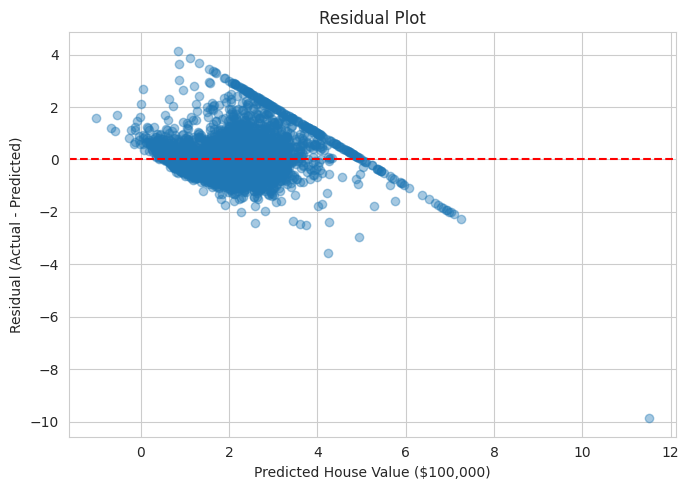

In [21]:
# Plot residuals against predicted values

plt.figure(figsize=(7, 5))

plt.scatter(
    y_pred_multiple,
    residuals,
    alpha=0.4
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title("Residual Plot")
plt.xlabel("Predicted House Value ($100,000)")
plt.ylabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()

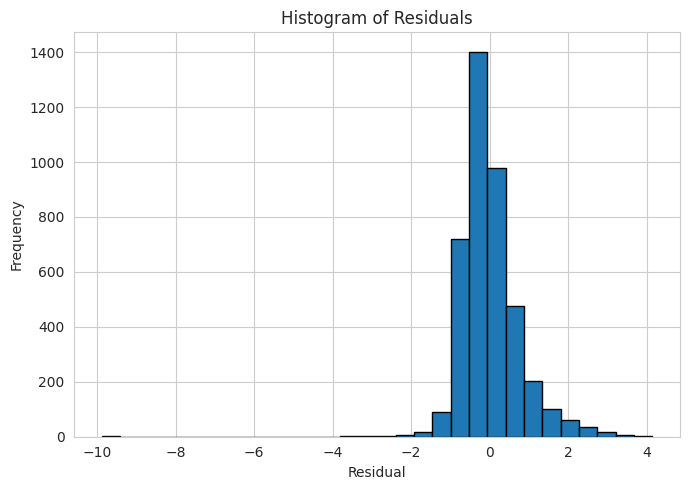

In [22]:
# Plot histogram of residuals

plt.figure(figsize=(7, 5))

plt.hist(
    residuals,
    bins=30,
    edgecolor="black"
)

plt.title("Histogram of Residuals")
plt.xlabel("Residual")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

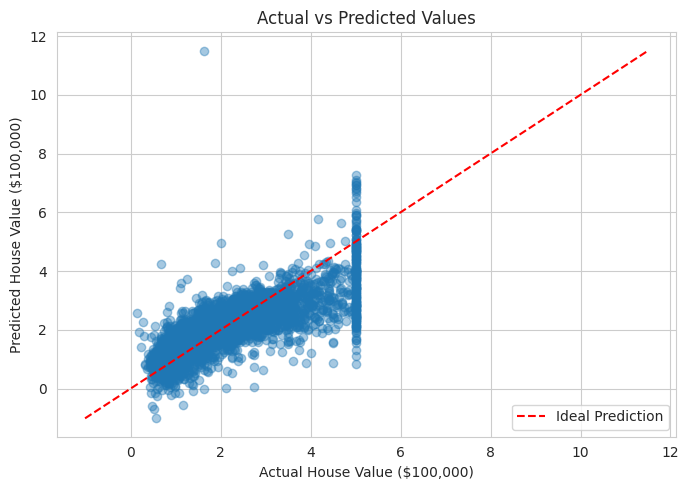

In [23]:
# Plot actual versus predicted values

plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    y_pred_multiple,
    alpha=0.4
)

minimum = min(y_test.min(), y_pred_multiple.min())
maximum = max(y_test.max(), y_pred_multiple.max())

# Ideal 45-degree line

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="red",
    linestyle="--",
    label="Ideal Prediction"
)

plt.title("Actual vs Predicted Values")
plt.xlabel("Actual House Value ($100,000)")
plt.ylabel("Predicted House Value ($100,000)")

plt.legend()
plt.tight_layout()
plt.show()

In [24]:
# Calculate VIF using training data

# Add constant for the intercept
from statsmodels.tools.tools import add_constant

X_vif = add_constant(X_train)

vif_data = pd.DataFrame()

vif_data["Feature"] = X_vif.columns

vif_data["VIF"] = [
    variance_inflation_factor(
        X_vif.values,
        i
    )
    for i in range(X_vif.shape[1])
]

# Remove the intercept from the displayed results
vif_data = vif_data[
    vif_data["Feature"] != "const"
]

print("Variance Inflation Factor:")
display(vif_data.sort_values("VIF", ascending=False).round(3))

Variance Inflation Factor:


,Feature,VIF
7,Latitude,9.206
8,Longitude,8.876
3,AveRooms,7.917
4,AveBedrms,6.609
1,MedInc,2.540
2,HouseAge,1.237
5,Population,1.135
6,AveOccup,1.010


In [25]:
# Calculate VIF using training data

# Add constant for the intercept
from statsmodels.tools.tools import add_constant

X_vif = add_constant(X_train)

vif_data = pd.DataFrame()

vif_data["Feature"] = X_vif.columns

vif_data["VIF"] = [
    variance_inflation_factor(
        X_vif.values,
        i
    )
    for i in range(X_vif.shape[1])
]

# Remove the intercept from the displayed results
vif_data = vif_data[
    vif_data["Feature"] != "const"
]

print("Variance Inflation Factor:")
display(vif_data.sort_values("VIF", ascending=False).round(3))

Variance Inflation Factor:


,Feature,VIF
7,Latitude,9.206
8,Longitude,8.876
3,AveRooms,7.917
4,AveBedrms,6.609
1,MedInc,2.540
2,HouseAge,1.237
5,Population,1.135
6,AveOccup,1.010


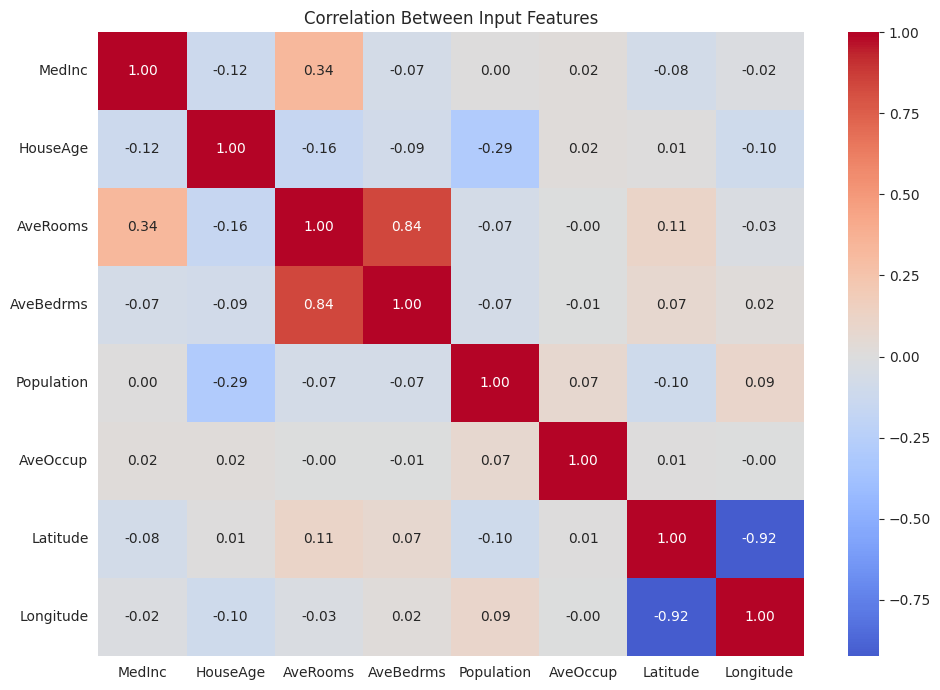

Feature pairs with absolute correlation >= 0.7:
AveRooms and AveBedrms Correlation: 0.836
Latitude and Longitude Correlation: -0.924


In [26]:
# Check correlation among input features

feature_corr = X_train.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    feature_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlation Between Input Features")
plt.tight_layout()
plt.show()

# Identify strongly correlated pairs

print("Feature pairs with absolute correlation >= 0.7:")

for i in range(len(feature_corr.columns)):
    for j in range(i + 1, len(feature_corr.columns)):

        value = feature_corr.iloc[i, j]

        if abs(value) >= 0.7:
            print(
                feature_corr.columns[i],
                "and",
                feature_corr.columns[j],
                "Correlation:",
                round(value, 3)
            )

## 10. Prediction for a New Example

A new housing example is created using the median values of the training features.

This provides a reasonable example within the observed feature ranges. The trained multiple linear regression model predicts the median house value for this new record.

The prediction is reported in the original target units and converted into dollars.

The result is an estimate rather than a guaranteed real-world house price. Predictions outside the training data range would involve extrapolation and should be treated with caution.

In [27]:
# Create a new example using training feature medians

new_example = X_train.median().to_frame().T

print("New Example:")
display(new_example)

# Check feature ranges

print("\nTraining Range Check:")

for feature in X.columns:

    value = new_example[feature].iloc[0]

    minimum = X_train[feature].min()
    maximum = X_train[feature].max()

    print(
        feature,
        "Within training range:",
        minimum <= value <= maximum
    )

# Predict house value

new_prediction = multiple_model.predict(new_example)[0]

print("\nPredicted House Value:")
print(f"{new_prediction:.4f} units of $100,000")

print(
    f"Approximate House Value: ${new_prediction * 100000:,.2f}"
)

New Example:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,3.5458,29.0,5.235874,1.049286,1167.0,2.81724,34.26,-118.51



Training Range Check:
MedInc Within training range: True
HouseAge Within training range: True
AveRooms Within training range: True
AveBedrms Within training range: True
Population Within training range: True
AveOccup Within training range: True
Latitude Within training range: True
Longitude Within training range: True

Predicted House Value:
2.0300 units of $100,000
Approximate House Value: $203,002.36


## 11. Conclusion

The California Housing dataset was used to implement multiple linear regression. Eight numerical features were selected to predict median house value.

The regression coefficients were calculated manually using the normal equations and verified using Scikit-learn. A single-feature model and a multiple-feature model were developed and evaluated using test data.

The models were compared using MAE, MSE, RMSE, R², and adjusted R². Residual plots, correlation analysis, and VIF were used to examine model performance and regression assumptions.

The multiple-feature model is considered preferable if the additional features improve prediction performance on unseen data sufficiently to justify the added complexity.

The model has limitations because it assumes linear relationships and may be affected by multicollinearity, outliers, and other factors not included in the dataset. It should not be used as the sole basis for real-estate buying or investment decisions.

In [28]:
# Generate a summary of the model comparison

print("FINAL MODEL COMPARISON")
print("-----------------------")

print("Single-feature model")
print("Feature:", best_feature)
print("Test MAE:", single_metrics["MAE"])
print("Test RMSE:", single_metrics["RMSE"])
print("Test R2:", single_metrics["R2"])
print("Test Adjusted R2:", single_metrics["Adjusted R2"])

print("\nMultiple-feature model")
print("Number of features:", X_train.shape[1])
print("Test MAE:", multiple_metrics["MAE"])
print("Test RMSE:", multiple_metrics["RMSE"])
print("Test R2:", multiple_metrics["R2"])
print("Test Adjusted R2:", multiple_metrics["Adjusted R2"])

print("\nDecision:")

if (
    multiple_metrics["RMSE"] < single_metrics["RMSE"]
    and multiple_metrics["R2"] > single_metrics["R2"]
):
    print(
        "The multiple-feature model improves both test RMSE "
        "and test R2."
    )
else:
    print(
        "The additional features do not improve both test "
        "RMSE and test R2. Consider model simplicity."
    )

FINAL MODEL COMPARISON
-----------------------
Single-feature model
Feature: MedInc
Test MAE: 0.629908653009376
Test RMSE: 0.8420901241414455
Test R2: 0.45885918903846656
Test Adjusted R2: 0.4587280351821986

Multiple-feature model
Number of features: 8
Test MAE: 0.5332001304956561
Test RMSE: 0.745581383012776
Test R2: 0.5757877060324512
Test Adjusted R2: 0.5749637928613562

Decision:
The multiple-feature model improves both test RMSE and test R2.


## 12. Decision Log

| Decision | Reason |
|---|---|
| Selected California Housing dataset | It contains multiple numerical features and a continuous target. |
| Selected eight input features | The features may help explain house value. |
| Checked missing and duplicate records | To ensure data quality before model fitting. |
| Used an 80:20 train-test split | To evaluate performance on unseen data. |
| Selected the strongest single feature | To establish a simple baseline model. |
| Used multiple linear regression | To examine whether additional features improve predictions. |
| Calculated VIF and feature correlations | To identify possible multicollinearity. |
| Examined residual plots | To check linear regression assumptions. |
| Compared test-set metrics | To decide whether the extra features justify the complexity. |
| Predicted a new example within training ranges | To avoid unnecessary extrapolation. |

### Limitations

The model assumes approximately linear relationships between the selected features and the target. It may not capture non-linear effects or all factors that influence housing prices.

The California Housing dataset also has a maximum target value, so the model should not be used for unrestricted price predictions.

The model describes statistical relationships and does not establish that a particular feature causes house prices to change.